# MNIST, four training settings

The sections through "What the runs show" are the legacy experiment. Initialization changed with batch norm there, so that contrast is confounded. The last section is the controlled He comparison. It reads saved results and does not train.

Question: on the official MNIST split, what do L2 and batch norm change for this fixed manual network?

The forward pass, backward pass, and updates live in `main.py`. PyTorch stores tensors and loads the files. It is not used as `nn.Linear` or as the loss.

## Protocol

- Official torchvision MNIST: 60,000 train / 10,000 test. Pixels are divided by 255 everywhere.
- Validation is a seeded 20% holdout of the training split (`split seed 21`): 48,000 fit / 12,000 validation. The test split is not used to build that holdout and is not used to stop or to choose a checkpoint.
- Architecture `[784, 20, 7, 5, 10]`. Hidden layers are affine + ReLU. Batch norm, when on, sits after ReLU. The output is affine + softmax. The loss is mean cross-entropy, plus `lambd / (2m) * ||W||^2` when `lambd > 0`.
- Shared settings: learning rate `0.009`, batch size 64, Adam is not used (plain gradient steps), maximum 300 epochs, patience 20 on validation cost. The restored weights are the lowest validation cost, including batch-norm running statistics.
- Variants: baseline, L2 (`lambd=0.04`), batch norm, batch norm + L2. The split, learning rate, batch size, and architecture stay fixed.
- Init/shuffle seeds 21, 7, and 99. Seed 21 is the paired comparison. The other two seeds are the same split with a different init and shuffle. Test accuracy is averaged after each seed has selected its own checkpoint. The seed is not chosen from the test set.

## Run plan from a capacity check

This machine is CPU-only (`torch 2.14.1+cpu`, 20 logical CPUs, 16 GB RAM, no CUDA). One full-data epoch took about 0.9 s without batch norm and 1.6 s with batch norm and L2. Three hundred epochs is a ceiling, not a time budget: patience stops a run that has stopped improving. Twelve runs are therefore on the order of an hour if they all reach the ceiling, and less if they stop earlier.


In [1]:
%matplotlib inline

import platform
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch
import torchvision

ROOT = Path.cwd()
if not (ROOT / "main.py").exists():
    raise FileNotFoundError("Start Jupyter in the folder that contains main.py.")
sys.path.insert(0, str(ROOT))

from main import (
    DEFAULT_LAYER_DIMS,
    check_gradients,
    confusion_matrix,
    get_device,
    load_mnist,
    predict,
    train_model,
    weight_norms,
)

print("platform", platform.platform())
print("python", platform.python_version())
print("torch", torch.__version__, "cuda", torch.cuda.is_available(), "threads", torch.get_num_threads())
print("torchvision", torchvision.__version__)
print("device", get_device())
print("layer_dims", DEFAULT_LAYER_DIMS)


platform Windows-11-10.0.26200-SP0
python 3.13.2
torch 2.14.1+cpu cuda False threads 14
torchvision 0.29.1+cpu
device cpu
layer_dims [784, 20, 7, 5, 10]


## Gradient check

Manual backward is compared with autograd on a 5-4-3 fixture, with and without batch norm and L2. Finite differences cover the cases without batch norm. This does not replace the MNIST runs below.


In [2]:
gradient_report = check_gradients(seed=0)
for case in gradient_report["cases"]:
    print(case)
    if case["max_abs_autograd"] > 1e-5:
        raise AssertionError(case)
    if case["max_abs_numeric"] is not None and case["max_abs_numeric"] > 1e-2:
        raise AssertionError(case)
print("fixture", gradient_report["fixture"])


{'use_bnorm': False, 'lambd': 0.0, 'max_abs_autograd': 2.7939677238464355e-08, 'max_abs_numeric': 0.0}
{'use_bnorm': False, 'lambd': 0.1, 'max_abs_autograd': 2.7939677238464355e-08, 'max_abs_numeric': 0.00017652101814746857}
{'use_bnorm': True, 'lambd': 0.0, 'max_abs_autograd': 1.1920928955078125e-07, 'max_abs_numeric': None}
{'use_bnorm': True, 'lambd': 0.05, 'max_abs_autograd': 1.1920928955078125e-07, 'max_abs_numeric': None}
fixture {'examples': 6, 'layer_dims': [5, 4, 3]}


## Data


In [3]:
data = load_mnist(root=ROOT / "data", val_fraction=0.2, seed=21)
print("normalization", data["normalization"])
print("train", tuple(data["x_train"].shape), "val", tuple(data["x_val"].shape), "test", tuple(data["x_test"].shape))
assert data["x_train"].shape[1] == 48000
assert data["x_val"].shape[1] == 12000
assert data["x_test"].shape[1] == 10000


normalization pixel / 255
train (784, 48000) val (784, 12000) test (784, 10000)


## Train

Each variant is selected on validation cost only. A finished checkpoint is reloaded if this cell is run again, so an interrupted notebook does not throw away a completed run. Test accuracy is computed in the next cell.


In [4]:
VARIANTS = [
    {"name": "baseline", "use_bnorm": False, "lambd": 0.0},
    {"name": "l2", "use_bnorm": False, "lambd": 0.04},
    {"name": "batchnorm", "use_bnorm": True, "lambd": 0.0},
    {"name": "batchnorm_l2", "use_bnorm": True, "lambd": 0.04},
]
LEARNING_RATE = 0.009
MAX_EPOCHS = 300
BATCH_SIZE = 64
PATIENCE = 20
SPLIT_SEED = 21
SEEDS = (21, 7, 99)
CHECKPOINT_DIR = ROOT / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)

runs = []
for seed in SEEDS:
    for variant in VARIANTS:
        path = CHECKPOINT_DIR / f"{variant['name']}_seed{seed}.pt"
        if path.exists():
            saved = torch.load(path, map_location="cpu", weights_only=False)
            parameters = saved["parameters"]
            history = saved["history"]
            print("loaded", path.name, "epochs", history["epochs_ran"], "best", history["best_epoch"], flush=True)
        else:
            print("training", variant["name"], "seed", seed, flush=True)
            parameters, history = train_model(
                data["x_train"], data["y_train"], data["x_val"], data["y_val"],
                DEFAULT_LAYER_DIMS,
                learning_rate=LEARNING_RATE,
                num_iterations=MAX_EPOCHS,
                batch_size=BATCH_SIZE,
                use_bnorm=variant["use_bnorm"],
                lambd=variant["lambd"],
                patience=PATIENCE,
                seed=seed,
                log_every=20,
            )
            parameters = {name: value.detach().cpu() for name, value in parameters.items()}
            torch.save({"parameters": parameters, "history": history, "variant": variant, "seed": seed}, path)
        train_metrics = predict(data["x_train"], data["y_train"], parameters, variant["use_bnorm"])
        val_metrics = predict(data["x_val"], data["y_val"], parameters, variant["use_bnorm"])
        runs.append({
            "name": variant["name"],
            "use_bnorm": variant["use_bnorm"],
            "lambd": variant["lambd"],
            "seed": seed,
            "parameters": parameters,
            "history": history,
            "train_accuracy": train_metrics["accuracy"],
            "val_accuracy": val_metrics["accuracy"],
        })
        print(
            variant["name"], "seed", seed,
            "epochs", history["epochs_ran"],
            "best_epoch", history["best_epoch"],
            "train", round(train_metrics["accuracy"], 4),
            "val", round(val_metrics["accuracy"], 4),
            flush=True,
        )


training baseline seed 21


epoch 20 train_cost 0.3162 val_cost 0.3349 train_acc 0.9183 val_acc 0.9068


epoch 40 train_cost 0.1787 val_cost 0.2405 train_acc 0.9491 val_acc 0.9327


epoch 60 train_cost 0.1398 val_cost 0.2234 train_acc 0.9633 val_acc 0.9379


epoch 80 train_cost 0.1169 val_cost 0.2279 train_acc 0.9686 val_acc 0.9408


epoch 86 train_cost 0.1117 val_cost 0.2346 train_acc 0.9692 val_acc 0.9386 stop


... (75 outputs left out)

epoch 60 train_cost 0.1663 val_cost 0.2129 train_acc 0.9719 val_acc 0.9455


epoch 80 train_cost 0.1516 val_cost 0.2053 train_acc 0.9757 val_acc 0.9461


epoch 90 train_cost 0.1619 val_cost 0.2085 train_acc 0.9730 val_acc 0.9455 stop


batchnorm_l2 seed 99 epochs 90 best_epoch 69 train 0.9743 val 0.9482


## Held-out test

Selection is already finished. This cell is the only place that reads the official test split.


In [5]:
for run in runs:
    test_metrics = predict(data["x_test"], data["y_test"], run["parameters"], run["use_bnorm"])
    run["test_accuracy"] = test_metrics["accuracy"]
    run["test_correct"] = test_metrics["correct"]
    run["test_total"] = test_metrics["total"]
    print(
        run["name"], "seed", run["seed"],
        "test", round(test_metrics["accuracy"], 4),
        f"{test_metrics['correct']}/{test_metrics['total']}",
    )


baseline seed 21 test 0.942 9420/10000
l2 seed 21 test 0.9464 9464/10000
batchnorm seed 21 test 0.949 9490/10000
batchnorm_l2 seed 21 test 0.9491 9491/10000
baseline seed 7 test 0.934 9340/10000
l2 seed 7 test 0.9354 9354/10000
batchnorm seed 7 test 0.9528 9528/10000
batchnorm_l2 seed 7 test 0.9498 9498/10000
baseline seed 99 test 0.9236 9236/10000
l2 seed 99 test 0.923 9230/10000
batchnorm seed 99 test 0.951 9510/10000
batchnorm_l2 seed 99 test 0.9535 9535/10000


## Learning curves

Seed 21 is the paired comparison. Train cost is the mean mini-batch cost from that epoch, so the L2 runs include the penalty. Validation cost is the full validation set in eval mode. Accuracy uses eval-mode batch-norm statistics.


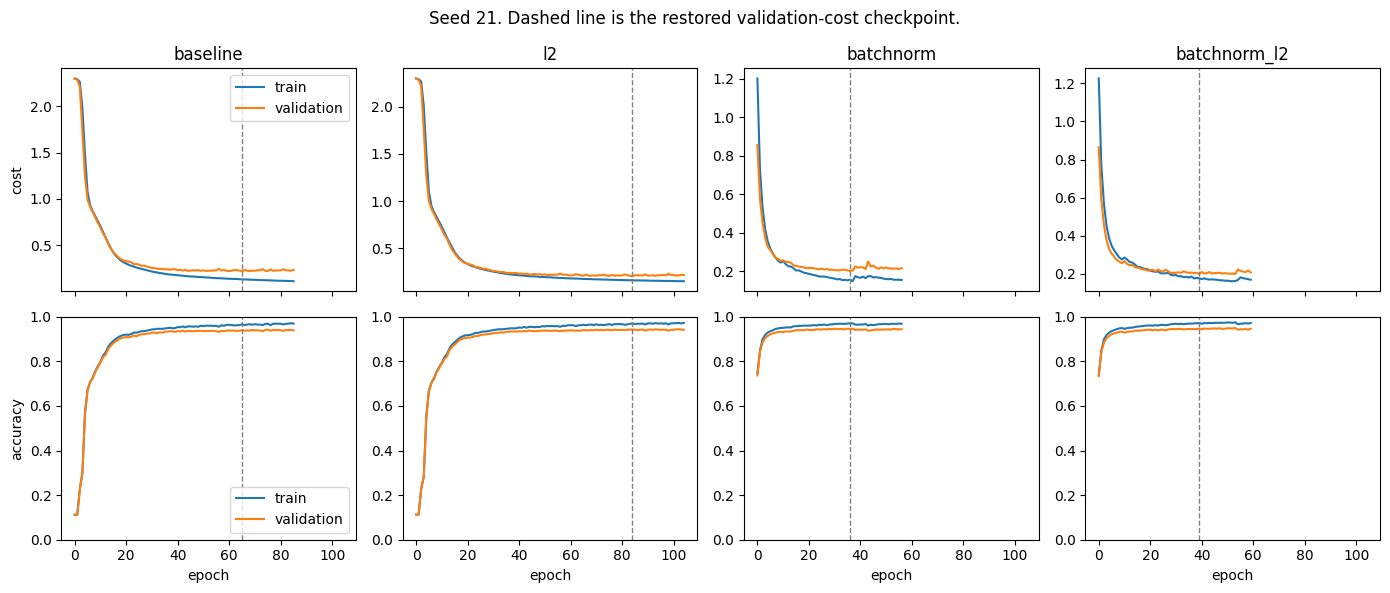

In [6]:
paired = [run for run in runs if run["seed"] == 21]
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
for column, run in enumerate(paired):
    history = run["history"]
    axes[0, column].plot(history["train_cost"], label="train")
    axes[0, column].plot(history["val_cost"], label="validation")
    axes[0, column].axvline(history["best_epoch"], color="gray", linestyle="--", linewidth=1)
    axes[0, column].set_title(run["name"])
    axes[0, column].set_ylabel("cost" if column == 0 else "")
    axes[1, column].plot(history["train_accuracy"], label="train")
    axes[1, column].plot(history["val_accuracy"], label="validation")
    axes[1, column].axvline(history["best_epoch"], color="gray", linestyle="--", linewidth=1)
    axes[1, column].set_xlabel("epoch")
    axes[1, column].set_ylabel("accuracy" if column == 0 else "")
    axes[1, column].set_ylim(0, 1)
axes[0, 0].legend()
axes[1, 0].legend()
fig.suptitle("Seed 21. Dashed line is the restored validation-cost checkpoint.")
fig.tight_layout()
plt.show()


## Comparison

Mean and sample standard deviation are over the three init/shuffle seeds. The test column was not used to pick epochs.


variant        seed  epochs   best    train      val     test
baseline         21      86     65   0.9658   0.9391   0.9420
l2               21     105     84   0.9695   0.9429   0.9464
batchnorm        21      57     36   0.9706   0.9448   0.9490
batchnorm_l2     21      60     39   0.9711   0.9472   0.9491
baseline          7     107     86   0.9638   0.9302   0.9340
l2                7     128    107   0.9637   0.9302   0.9354
batchnorm         7      80     59   0.9757   0.9452   0.9528
batchnorm_l2      7      93     72   0.9776   0.9473   0.9498
baseline         99     111     90   0.9505   0.9193   0.9236
l2               99     131    110   0.9522   0.9164   0.9230
batchnorm        99      68     47   0.9717   0.9466   0.9510
batchnorm_l2     99      90     69   0.9743   0.9482   0.9535

variant          val mean    val std  test mean   test std
baseline           0.9295     0.0099     0.9332     0.0092
l2                 0.9299     0.0133     0.9349     0.0117
batchnorm       

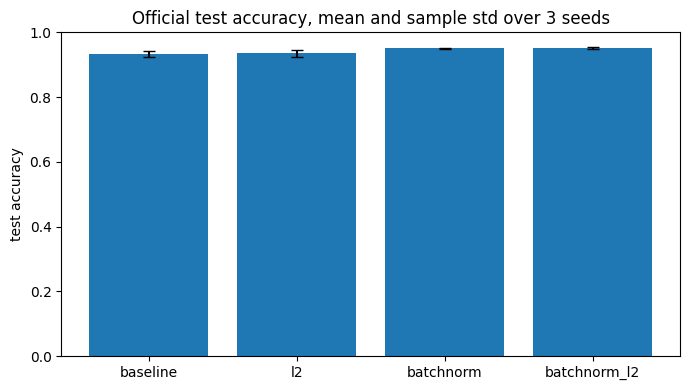

In [7]:
import statistics

print(f"{'variant':<14} {'seed':>4} {'epochs':>7} {'best':>6} {'train':>8} {'val':>8} {'test':>8}")
for run in runs:
    print(
        f"{run['name']:<14} {run['seed']:>4} {run['history']['epochs_ran']:>7} "
        f"{run['history']['best_epoch']:>6} {run['train_accuracy']:>8.4f} "
        f"{run['val_accuracy']:>8.4f} {run['test_accuracy']:>8.4f}"
    )

print()
print(f"{'variant':<14} {'val mean':>10} {'val std':>10} {'test mean':>10} {'test std':>10}")
for variant in VARIANTS:
    group = [run for run in runs if run["name"] == variant["name"]]
    val = [run["val_accuracy"] for run in group]
    test = [run["test_accuracy"] for run in group]
    print(
        f"{variant['name']:<14} {statistics.mean(val):>10.4f} {statistics.stdev(val):>10.4f} "
        f"{statistics.mean(test):>10.4f} {statistics.stdev(test):>10.4f}"
    )

fig, ax = plt.subplots(figsize=(7, 4))
names = [variant["name"] for variant in VARIANTS]
means = []
stds = []
for variant in VARIANTS:
    test = [run["test_accuracy"] for run in runs if run["name"] == variant["name"]]
    means.append(statistics.mean(test))
    stds.append(statistics.stdev(test))
ax.bar(names, means, yerr=stds, capsize=4)
ax.set_ylim(0, 1)
ax.set_ylabel("test accuracy")
ax.set_title("Official test accuracy, mean and sample std over 3 seeds")
fig.tight_layout()
plt.show()


## Test confusion matrices

Seed 21 only, after that seed's validation checkpoint was restored. Rows are the true class.


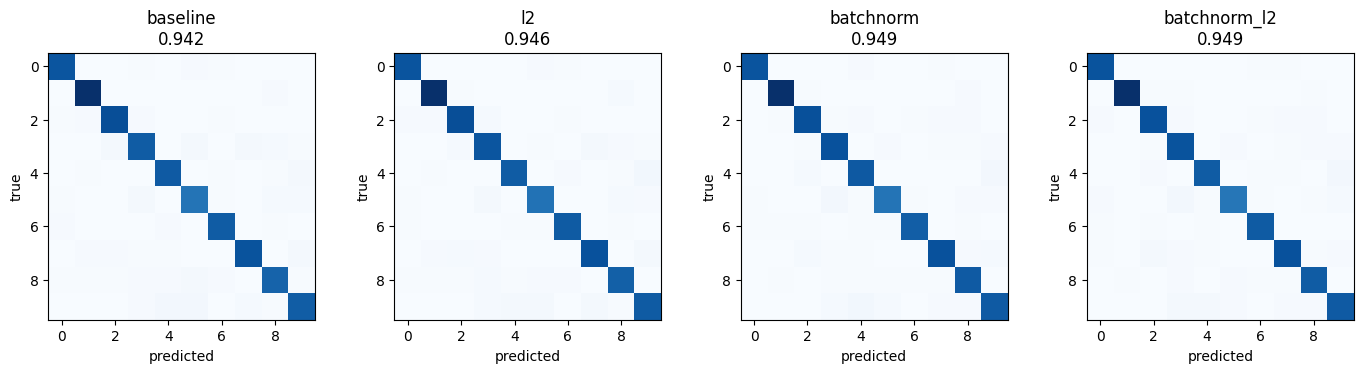

L2 weight norms, seed 21, baseline vs l2
baseline {'W1': 6.396697044372559, 'W2': 5.405289649963379, 'W3': 5.373213768005371, 'W4': 5.6964521408081055}
l2 {'W1': 6.3357625007629395, 'W2': 5.362521171569824, 'W3': 5.313912868499756, 'W4': 5.522260665893555}
batchnorm {'W1': 7.3411359786987305, 'W2': 3.821951389312744, 'W3': 2.8100802898406982, 'W4': 6.302443027496338}
batchnorm_l2 {'W1': 6.501905918121338, 'W2': 3.2552764415740967, 'W3': 2.3629708290100098, 'W4': 5.7464704513549805}


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for axis, run in zip(axes, paired):
    matrix = confusion_matrix(data["x_test"], data["y_test"], run["parameters"], run["use_bnorm"])
    axis.imshow(matrix.numpy(), cmap="Blues")
    axis.set_title(f"{run['name']}\n{run['test_accuracy']:.3f}")
    axis.set_xlabel("predicted")
    axis.set_ylabel("true")
    run["confusion"] = matrix.tolist()
fig.tight_layout()
plt.show()

print("L2 weight norms, seed 21, baseline vs l2")
by_name = {run["name"]: run for run in paired}
print("baseline", weight_norms(by_name["baseline"]["parameters"]))
print("l2", weight_norms(by_name["l2"]["parameters"]))
print("batchnorm", weight_norms(by_name["batchnorm"]["parameters"]))
print("batchnorm_l2", weight_norms(by_name["batchnorm_l2"]["parameters"]))


## What the runs show

The gradient check matched autograd to about `1e-7`, and finite differences on the non-batch-norm fixture stayed under `2e-4`. That check is a 6-row network. The numbers below are the full MNIST runs.

On seed 21, the paired comparison, restored validation checkpoints reach test accuracy 0.9420 (baseline), 0.9464 (L2), 0.9490 (batch norm), and 0.9491 (batch norm + L2). Across seeds 21, 7, and 99 the test means are 0.9332, 0.9349, 0.9509, and 0.9508, with sample standard deviations 0.0092, 0.0117, 0.0019, and 0.0024. Batch norm is the change that moves accuracy and tightens the seed spread. L2 at `lambd=0.04` does not separate from the baseline spread. With batch norm already on, adding L2 leaves the test mean essentially unchanged and gives the smallest validation spread (0.0006).

Seed 21 weight norms are slightly lower in every layer for L2 than for the baseline. Batch norm uses He scaling, so its norms are not an L2 comparison against the baseline. The logged cost includes the L2 penalty when `lambd > 0`, so those loss curves are not on the same scale as the unpenalized runs. Accuracy is the comparison that stays on one scale.

Every run stopped on patience and restored an earlier validation-cost checkpoint. Baseline seed 99 is the weak draw (test 0.9236) and accounts for most of the baseline spread. Three init seeds on one 48,000/12,000 split are a small sample. The widths stay `[784, 20, 7, 5, 10]`.


## Controlled comparison

The sections above are the legacy experiment. Those batch-norm runs also switched to He initialization, so they are not an isolated batch-norm contrast. The original outputs are unchanged.

This section does not train. Every controlled variant uses initialization he. The run is python run_controlled.py, and the numbers below are read from results/controlled_summary.md after that command has finished.


In [1]:
from pathlib import Path

ROOT = Path.cwd()
CONTROLLED = {
    "experiment_id": "controlled_he_v1",
    "initialization": "he",
    "applies_to_every_variant": True,
    "variants": ["baseline", "l2", "batchnorm", "batchnorm_l2"],
    "seeds": [21, 7, 99],
    "split_seed": 21,
    "learning_rate": 0.009,
    "batch_size": 64,
    "max_epochs": 300,
    "patience": 20,
    "selection_metric": "val_cost",
}
print(CONTROLLED)
summary_path = ROOT / "results" / "controlled_summary.md"
if summary_path.exists():
    print(summary_path.read_text(encoding="utf-8"))
else:
    print("Controlled results are not in results/ yet. Run: python run_controlled.py")
    print("This cell does not train.")


{'experiment_id': 'controlled_he_v1', 'initialization': 'he', 'applies_to_every_variant': True, 'variants': ['baseline', 'l2', 'batchnorm', 'batchnorm_l2'], 'seeds': [21, 7, 99], 'split_seed': 21, 'learning_rate': 0.009, 'batch_size': 64, 'max_epochs': 300, 'patience': 20, 'selection_metric': 'val_cost'}
# Controlled MNIST ablation (He initialization fixed)

This is the primary comparison. Every variant uses `initialization="he"`.
Batch norm does not choose the initializer. The legacy confounded numbers
remain in `results/legacy_mnist_summary.md`.

## Seeds

Split seed 21 draws the 48,000 / 12,000 partition once and is shared by every run.
Seeds 21, 7, and 99 each seed weight initialization and the minibatch permutation.
They do not redraw the split. The same seed produces the same initial W and b
for the batch-norm and non-batch-norm variants. Gamma and beta start at ones and zeros.

## Selection

Each checkpoint is the first minimum of validation cost (cross-entropy plus the
L2 term 